# 01 — EDA & Uji Parallel Trends

Tujuan notebook ini **bukan** mengukur efek frost, melainkan menjawab satu pertanyaan
yang menentukan apakah seluruh desain DiD boleh dilanjutkan:

> Sebelum frost Juli 2021, apakah harga Arabika dan Robusta benar-benar bergerak sejajar?

DiD mengasumsikan bahwa **tanpa** frost, selisih harga kedua kopi akan tetap seperti tren
sebelumnya. Asumsi itu tidak bisa dibuktikan, tapi bisa **digagalkan** — dan itulah yang diuji
di sini.

Periode mulai **Maret 2006**, mengikuti `REGRESSION_START`, karena `brl_usd` punya 65 bulan
kosong sebelum tanggal itu (lihat CLAUDE.md §2.3).

In [1]:
import sys
from pathlib import Path

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from src.ingestion.events import load_events
from src.processing.build_panel import REGRESSION_START, build_panel

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

EVENT = pd.Timestamp("2021-07-01")
BASE = pd.Timestamp("2021-06-01")   # bulan terakhir sebelum frost
PRE_MONTHS = 36

panel = build_panel(weather_end="20260831").loc[REGRESSION_START:]
events = load_events("../data/events.csv")

print(f"{len(panel)} bulan: {panel.index.min():%Y-%m} s/d {panel.index.max():%Y-%m}")
print("NaN per kolom:", panel.isna().sum().to_dict())
panel.head()

Matplotlib is building the font cache; this may take a moment.


246 bulan: 2006-03 s/d 2026-08
NaN per kolom: {'arabica_usd_kg': 0, 'robusta_usd_kg': 0, 'frost_regions': 0, 'frost_days_total': 0, 'min_tmin': 0, 'rain_anom': 0, 'brl_usd': 0}


,arabica_usd_kg,robusta_usd_kg,frost_regions,frost_days_total,min_tmin,rain_anom,brl_usd
month,,,,,,,
2006-03-01,2.51,1.31,0,0,14.64,44.186087,2.175450
2006-04-01,2.54,1.33,0,0,11.55,-8.399783,2.124861
2006-05-01,2.41,1.32,0,0,6.84,-20.113261,2.171986
2006-06-01,2.27,1.33,0,0,7.91,-7.134058,2.248123
2006-07-01,2.31,1.42,0,0,7.66,-5.478551,2.179538


## 1. Gambaran umum harga

**Hipotesis:** kedua harga bergerak searah dalam jangka panjang karena sama-sama kopi dan
menghadapi permintaan global yang sama, tetapi Arabika lebih mahal dan lebih bergejolak
karena lebih sensitif terhadap cuaca.

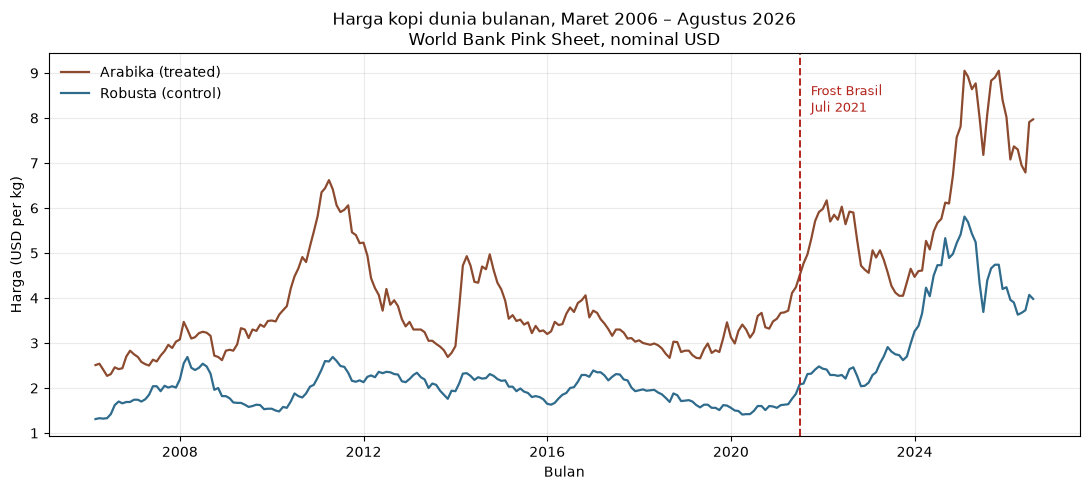

       arabica_usd_kg  robusta_usd_kg
count          246.00          246.00
mean             4.21            2.33
std              1.57            0.92
min              2.27            1.31
25%              3.08            1.74
50%              3.58            2.10
75%              4.94            2.38
max              9.05            5.81


In [2]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(panel.index, panel.arabica_usd_kg, label="Arabika (treated)", color="#8C4A2F", lw=1.6)
ax.plot(panel.index, panel.robusta_usd_kg, label="Robusta (control)", color="#2F6B8C", lw=1.6)

ax.axvline(EVENT, color="#B3241C", ls="--", lw=1.4)
ax.annotate("Frost Brasil\nJuli 2021", xy=(EVENT, ax.get_ylim()[1] * 0.95),
            xytext=(8, -6), textcoords="offset points",
            color="#B3241C", fontsize=9, va="top")

ax.set_title("Harga kopi dunia bulanan, Maret 2006 – Agustus 2026\n"
             "World Bank Pink Sheet, nominal USD")
ax.set_xlabel("Bulan")
ax.set_ylabel("Harga (USD per kg)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_harga_arabika_robusta.png", dpi=150)
plt.show()

print(panel[["arabica_usd_kg", "robusta_usd_kg"]].describe().round(2))

**Interpretasi:**

Arabika konsisten lebih mahal dari Robusta sepanjang 20 tahun, dan jarak keduanya melebar
tajam setelah 2021. Namun grafik ini **belum membuktikan apa pun** tentang frost: kenaikan
setelah Juli 2021 terjadi bersamaan dengan gangguan rantai pasok global pasca-COVID dan
inflasi komoditas secara umum. Justru karena itulah kita perlu kelompok kontrol — kenaikan
yang dialami *kedua* kopi bukan efek frost.

## 2. Harga terindeks (Juni 2021 = 100)

**Hipotesis:** jika frost hanya memukul Arabika, maka setelah Juli 2021 garis Arabika akan
naik meninggalkan Robusta. Sebelum Juli 2021, keduanya semestinya berimpit.

Basis Juni 2021 dipilih karena itu bulan terakhir sebelum frost.

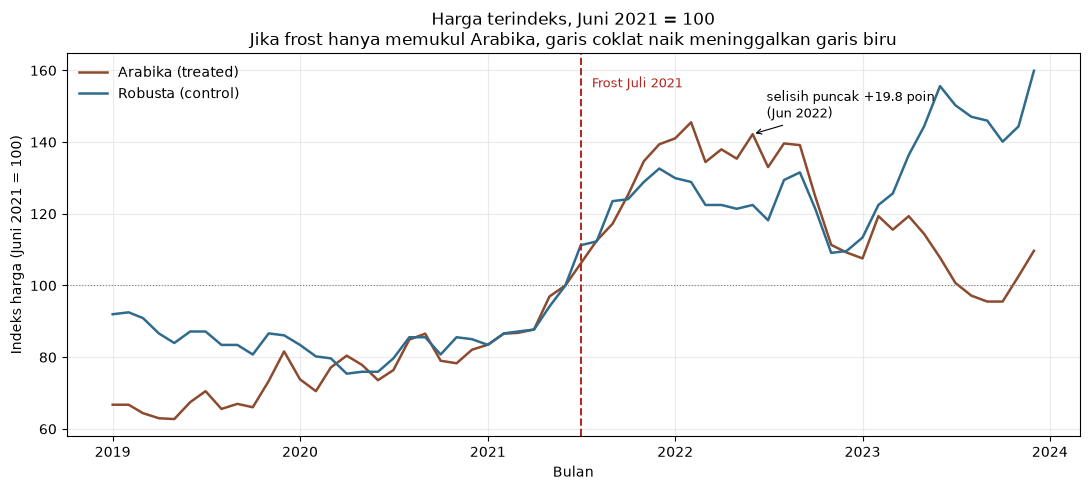

Selisih indeks (Arabika - Robusta) pada bulan kunci:
  2021-06: +0.0
  2021-11: +5.8
  2022-02: +16.6
  2022-06: +19.8
  2022-12: -0.4


In [3]:
window = panel.loc["2019-01-01":"2023-12-01"]
indexed = window[["arabica_usd_kg", "robusta_usd_kg"]] / panel.loc[BASE, ["arabica_usd_kg", "robusta_usd_kg"]] * 100

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(indexed.index, indexed.arabica_usd_kg, label="Arabika (treated)", color="#8C4A2F", lw=1.8)
ax.plot(indexed.index, indexed.robusta_usd_kg, label="Robusta (control)", color="#2F6B8C", lw=1.8)
ax.axhline(100, color="grey", lw=0.8, ls=":")
ax.axvline(EVENT, color="#B3241C", ls="--", lw=1.4)
ax.annotate("Frost Juli 2021", xy=(EVENT, indexed.max().max()), xytext=(8, -4),
            textcoords="offset points", color="#B3241C", fontsize=9, va="top")

gap = (indexed.arabica_usd_kg - indexed.robusta_usd_kg)
peak = gap.idxmax()
ax.annotate(f"selisih puncak {gap.max():+.1f} poin\n({peak:%b %Y})",
            xy=(peak, indexed.loc[peak, "arabica_usd_kg"]), xytext=(10, 12),
            textcoords="offset points", fontsize=9,
            arrowprops=dict(arrowstyle="->", lw=0.8))

ax.set_title("Harga terindeks, Juni 2021 = 100\nJika frost hanya memukul Arabika, garis coklat naik meninggalkan garis biru")
ax.set_xlabel("Bulan")
ax.set_ylabel("Indeks harga (Juni 2021 = 100)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_harga_terindeks.png", dpi=150)
plt.show()

print("Selisih indeks (Arabika - Robusta) pada bulan kunci:")
for d in ["2021-06-01", "2021-11-01", "2022-02-01", "2022-06-01", "2022-12-01"]:
    print(f"  {d[:7]}: {gap.loc[d]:+.1f}")

**Interpretasi:**

Polanya sesuai dugaan agronomis, bukan sesuai dugaan naif. Selisihnya **tidak** langsung
melebar di Juli 2021 — sampai Oktober 2021 masih datar. Divergensi baru mulai November 2021
(+5,8 poin), memuncak Juni 2022 (+19,8 poin), lalu kembali ke nol pada Desember 2022.

Jeda ~4 bulan itu masuk akal: frost Juli merusak **panen tahun berikutnya**, sehingga harga
baru bereaksi penuh ketika panen 2022 yang berkurang benar-benar terwujud. Artinya jendela
event study harus panjang (±18 bulan), bukan 1–2 bulan.

## 3. Uji parallel trends — secara visual

**Hipotesis:** pada 36 bulan sebelum frost, log-harga kedua kopi bergerak dengan kemiringan
yang serupa. Log dipakai supaya kemiringan garis bisa dibaca sebagai **persentase** perubahan,
sehingga dua seri dengan level harga berbeda tetap bisa dibandingkan.

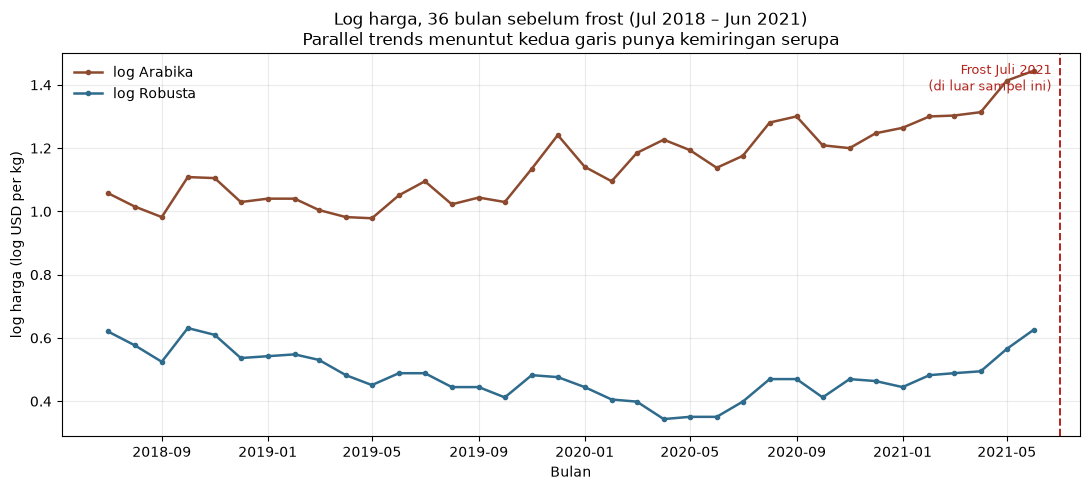

In [4]:
pre = panel.loc[BASE - pd.DateOffset(months=PRE_MONTHS - 1):BASE]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(pre.index, np.log(pre.arabica_usd_kg), label="log Arabika", color="#8C4A2F", lw=1.8, marker="o", ms=3)
ax.plot(pre.index, np.log(pre.robusta_usd_kg), label="log Robusta", color="#2F6B8C", lw=1.8, marker="o", ms=3)
ax.axvline(EVENT, color="#B3241C", ls="--", lw=1.4)
ax.annotate("Frost Juli 2021\n(di luar sampel ini)", xy=(EVENT, ax.get_ylim()[1]), xytext=(-6, -6),
            textcoords="offset points", color="#B3241C", fontsize=9, ha="right", va="top")

ax.set_title(f"Log harga, {PRE_MONTHS} bulan sebelum frost ({pre.index.min():%b %Y} – {pre.index.max():%b %Y})\n"
             "Parallel trends menuntut kedua garis punya kemiringan serupa")
ax.set_xlabel("Bulan")
ax.set_ylabel("log harga (log USD per kg)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_log_harga_pra_event.png", dpi=150)
plt.show()

**Interpretasi:**

Secara mata, keduanya sama-sama naik — tapi Arabika naik lebih curam, terutama sejak
pertengahan 2020. Ini sinyal peringatan: kalau Arabika memang sudah menanjak lebih cepat
**sebelum** frost, sebagian kenaikan pasca-frost bisa jadi cuma kelanjutan tren lama, bukan
akibat frost. Mata saja tidak cukup untuk memutuskan — perlu diuji secara numerik.

## 4. Uji parallel trends — secara numerik

**Hipotesis nol yang diuji:** selisih log-harga (`gap = log Arabika − log Robusta`) **tidak**
punya tren waktu pada periode pra-event. Kalau benar sejajar, kemiringan regresi
`gap ~ waktu` harus mendekati nol dan tidak signifikan secara statistik.

Kalau kemiringannya signifikan, artinya jarak kedua kopi sudah melebar sistematis sebelum
frost terjadi — dan DiD polos akan salah membaca tren lama itu sebagai efek frost.

In [5]:
def pretrend_test(months: int) -> dict:
    """Regress the log price gap on a time trend over the pre-event window."""
    sample = panel.loc[BASE - pd.DateOffset(months=months - 1):BASE]
    gap = np.log(sample.arabica_usd_kg) - np.log(sample.robusta_usd_kg)
    X = sm.add_constant(pd.Series(np.arange(len(sample)), index=sample.index, name="t"))
    fit = sm.OLS(gap, X).fit()
    return {
        "jendela": f"{months} bulan",
        "mulai": f"{sample.index.min():%Y-%m}",
        "slope": fit.params["t"],
        "std_error": fit.bse["t"],
        "p_value": fit.pvalues["t"],
        "r2": fit.rsquared,
        "sejajar?": "ya" if fit.pvalues["t"] > 0.05 else "TIDAK",
    }


main = pretrend_test(PRE_MONTHS)
sample = panel.loc[BASE - pd.DateOffset(months=PRE_MONTHS - 1):BASE]
gap_pre = np.log(sample.arabica_usd_kg) - np.log(sample.robusta_usd_kg)
X = sm.add_constant(pd.Series(np.arange(len(sample)), index=sample.index, name="t"))
fit = sm.OLS(gap_pre, X).fit()
print(fit.summary().tables[1])
print(f"\nKemiringan {main['slope']:+.5f} log poin per bulan "
      f"(≈ {(np.exp(main['slope']) - 1) * 100:+.2f}% per bulan), p = {main['p_value']:.4g}")
print(f"Akumulasi {PRE_MONTHS} bulan: {(np.exp(main['slope'] * PRE_MONTHS) - 1) * 100:+.1f}% pelebaran selisih")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.4368      0.018     24.368      0.000       0.400       0.473
t              0.0132      0.001     14.950      0.000       0.011       0.015

Kemiringan +0.01317 log poin per bulan (≈ +1.33% per bulan), p = 1.635e-16
Akumulasi 36 bulan: +60.7% pelebaran selisih


In [6]:
sens = pd.DataFrame([pretrend_test(m) for m in (12, 18, 24, 36, 48)])
sens_display = sens.assign(
    slope=lambda d: d.slope.round(5),
    std_error=lambda d: d.std_error.round(5),
    p_value=lambda d: d.p_value.round(4),
    r2=lambda d: d.r2.round(3),
)
print("Sensitivitas terhadap panjang jendela pra-event:")
print(sens_display.to_string(index=False))

Sensitivitas terhadap panjang jendela pra-event:
 jendela   mulai   slope  std_error  p_value    r2 sejajar?
12 bulan 2020-07 0.00386    0.00239   0.1382 0.206       ya
18 bulan 2020-01 0.00400    0.00212   0.0772 0.182       ya
24 bulan 2019-07 0.00969    0.00171   0.0000 0.594    TIDAK
36 bulan 2018-07 0.01317    0.00088   0.0000 0.868    TIDAK
48 bulan 2017-07 0.01167    0.00055   0.0000 0.908    TIDAK


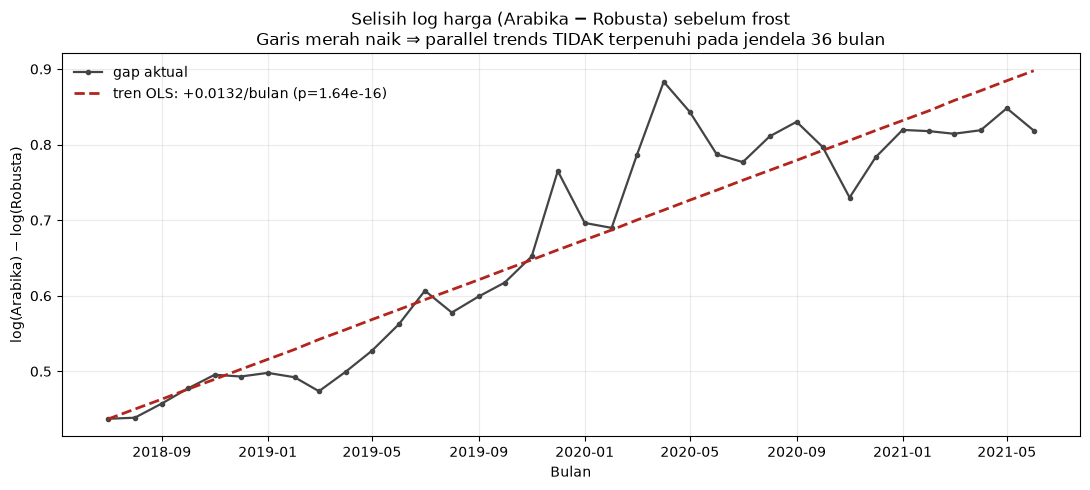

In [7]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(gap_pre.index, gap_pre.values, color="#444", lw=1.6, marker="o", ms=3, label="gap aktual")
ax.plot(gap_pre.index, fit.fittedvalues, color="#B3241C", lw=2, ls="--",
        label=f"tren OLS: {main['slope']:+.4f}/bulan (p={main['p_value']:.3g})")

ax.set_title("Selisih log harga (Arabika − Robusta) sebelum frost\n"
             "Garis merah naik ⇒ parallel trends TIDAK terpenuhi pada jendela 36 bulan")
ax.set_xlabel("Bulan")
ax.set_ylabel("log(Arabika) − log(Robusta)")
ax.legend(frameon=False)
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_uji_pretrend.png", dpi=150)
plt.show()

**Interpretasi — ini hasil penting dan harus dilaporkan apa adanya:**

Pada jendela **36 bulan, parallel trends GAGAL**. Kemiringannya **+0,0132 log poin per bulan**
(std error 0,00088, **p < 0,0001**, R² = 0,87) — artinya selisih Arabika–Robusta sudah melebar
sekitar **1,3% per bulan** sebelum frost, atau sekitar **+61%** secara akumulatif selama tiga
tahun itu. Ini jauh dari nol, dan sangat signifikan.

Tabel sensitivitas menunjukkan kesimpulannya **bergantung pada panjang jendela**:

| Jendela | slope/bulan | p-value | Sejajar? |
|---|---|---|---|
| 12 bulan | +0,0039 | 0,138 | ya |
| 18 bulan | +0,0040 | 0,077 | ya (nyaris) |
| 24 bulan | +0,0097 | <0,0001 | **tidak** |
| 36 bulan | +0,0132 | <0,0001 | **tidak** |
| 48 bulan | +0,0117 | <0,0001 | **tidak** |

Gate test di CLAUDE.md §4 yang menyimpulkan "parallel trends hold" memakai jendela **12 bulan**
— dan pada jendela itu memang lolos (p = 0,14). Tapi lolosnya rapuh: begitu jendela diperpanjang
ke 24 bulan, asumsinya runtuh.

**Konsekuensi untuk desain DiD:**

1. **DiD polos (dua periode, tanpa kontrol tren) akan bias ke atas.** Ia akan menghitung
   pelebaran yang sudah berjalan sejak 2018 sebagai efek frost.
2. **Estimasi harus menyertakan tren waktu spesifik-kelompok**, atau memakai jendela pra-event
   pendek (12 bulan) dan menyatakan pilihan itu terang-terangan.
3. **Event study jadi lebih penting daripada DiD dua-periode.** Koefisien per bulan relatif
   terhadap Juli 2021 akan memperlihatkan langsung apakah ada lonjakan di sekitar event atau
   sekadar garis lurus yang menanjak sejak lama.
4. Pilihan jendela **tidak boleh** ditentukan berdasarkan mana yang memberi hasil paling bagus.
   Itu seleksi berbasis hasil — masalah yang sama dengan menyetel ambang frost, yang sudah
   ditolak di CLAUDE.md §3.

**Catatan kejujuran:** ini melemahkan klaim kausal proyek, dan memang harus ditulis di bagian
limitations README, bukan disembunyikan.

## 5. Ringkasan

| Temuan | Status |
|---|---|
| Arabika & Robusta bergerak searah jangka panjang | ✅ terkonfirmasi |
| Divergensi pasca-frost tertunda ~4 bulan, puncak +19,8 poin (Jun 2022) | ✅ terkonfirmasi |
| Parallel trends pada 12 bulan pra-event | ✅ lolos (p = 0,14) |
| Parallel trends pada 24–48 bulan pra-event | ❌ **gagal** (p < 0,0001) |

**Langkah berikutnya (notebook 02):** DiD dengan tren spesifik-kelompok + event study,
memakai tanggal event terdokumentasi dari `data/events.csv`, bukan ambang cuaca.

In [8]:
print("Grafik tersimpan di reports/figures/:")
for f in sorted(FIG_DIR.glob("*.png")):
    print(" -", f.name, f"({f.stat().st_size // 1024} KB)")

Grafik tersimpan di reports/figures/:
 - 01_harga_arabika_robusta.png (123 KB)
 - 02_harga_terindeks.png (114 KB)
 - 03_log_harga_pra_event.png (99 KB)
 - 04_uji_pretrend.png (96 KB)
